## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings
warnings.filterwarnings("ignore")

## 1.Data Import

In [2]:
conn = sqlite3.connect('customer_churn.db')

sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table'
"""

tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}",conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")
# close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [3]:
# print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


## 2.Data Cleaning

In [4]:
# 1.df_db_customer
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [5]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
5245,3205-WPVZJ,arjun,India,Karnataka,Male,1997-05-30 00:00:00,NaN,None
5246,3205-OFSGQ,arjun,India,Uttar Pradesh,Male,1979-05-06 00:00:00,NaN,None
5247,3206-NTSZW,Madhav,India,Delhi,Men,1991-01-21 00:00:00,NaN,None
5248,3207-MBLHD,lalita,India,Delhi,Female,1995-04-28 00:00:00,drama,None
5249,3208-NAHKG,chitra,India,Meghalaya,Female,1994-06-07 00:00:00,NaN,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  5250 non-null   str   
 1   name        5250 non-null   str   
 2   country     4516 non-null   str   
 3   state       5250 non-null   str   
 4   gender      5250 non-null   str   
 5   dob         5250 non-null   str   
 6   interests   946 non-null    str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 328.3+ KB


In [7]:
# 1.1.rename column - name
# 1.2.drop columns - interest and pincode
# 1.3.change data type - dob
# 1.4.data standardization - gender
# 1.5.fix missing values - country

In [8]:
# 1.1.rename column - name
df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
...,...,...,...,...,...,...,...,...
5245,3205-WPVZJ,arjun,India,Karnataka,Male,1997-05-30 00:00:00,NaN,None
5246,3205-OFSGQ,arjun,India,Uttar Pradesh,Male,1979-05-06 00:00:00,NaN,None
5247,3206-NTSZW,Madhav,India,Delhi,Men,1991-01-21 00:00:00,NaN,None
5248,3207-MBLHD,lalita,India,Delhi,Female,1995-04-28 00:00:00,drama,None


In [9]:
# 1.2. handle missing values - interests and pincode
# df_db_customer.drop(df_db_customer.columns[-2:], axis=1) OR
# df_db_customer.drop(df_db_customer.columns[6:], axis=1) OR
df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
...,...,...,...,...,...,...
5245,3205-WPVZJ,arjun,India,Karnataka,Male,1997-05-30 00:00:00
5246,3205-OFSGQ,arjun,India,Uttar Pradesh,Male,1979-05-06 00:00:00
5247,3206-NTSZW,Madhav,India,Delhi,Men,1991-01-21 00:00:00
5248,3207-MBLHD,lalita,India,Delhi,Female,1995-04-28 00:00:00


In [10]:
# 1.3.change data type - dob
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     5250 non-null   str           
 1   customer_name  5250 non-null   str           
 2   country        4516 non-null   str           
 3   state          5250 non-null   str           
 4   gender         5250 non-null   str           
 5   dob            5250 non-null   datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 246.2 KB


In [11]:
# 1.4.data standardization - gender
# for checking unqiue values - df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men':'Male','Women':'Female'})
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [12]:
# 1.5.fix missing values - country
df_db_customer[df_db_customer['country'].isna()]
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
...,...,...
5245,India,Karnataka
5246,India,Uttar Pradesh
5247,India,Delhi
5248,India,Delhi


In [13]:
# 2.df_db_subscription
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [14]:
df_db_subscription.tail()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
5245,3205-WPVZJ,2020-11-10,Paid,2024-11-10,Standard,Annual,NaN,NaN,13.93,653,26
5246,3205-OFSGQ,2022-10-09,Refferal,2025-10-09,Basic,Monthly,NaN,NaN,7.06,253,7
5247,3206-NTSZW,2022-11-27,Paid,2026-11-27,Standard,Annual,NaN,NaN,14.31,634,62
5248,3207-MBLHD,2023-08-09,Refferal,2028-08-08,Standard,Annual,NaN,NaN,7.65,551,55
5249,3208-NAHKG,2020-07-17,Refferal,2025-07-17,Standard,Annual,NaN,NaN,17.49,1032,23


In [15]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               5250 non-null   str    
 1   subscription_start_date  5250 non-null   str    
 2   subscription_type        5250 non-null   str    
 3   renewal_date             5250 non-null   str    
 4   plan_type                5250 non-null   str    
 5   contract_type            5250 non-null   str    
 6   cancellation_date        1514 non-null   str    
 7   cancellation_reason      1514 non-null   str    
 8   monthly_charges          5250 non-null   float64
 9   cltv                     5250 non-null   int64  
 10  churn_score              5250 non-null   int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 451.3 KB


In [16]:
# 2.1.change data type - subscription_start_date, renewal_date, cancellation_date
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               5250 non-null   str           
 1   subscription_start_date  5250 non-null   datetime64[us]
 2   subscription_type        5250 non-null   str           
 3   renewal_date             5250 non-null   datetime64[us]
 4   plan_type                5250 non-null   str           
 5   contract_type            5250 non-null   str           
 6   cancellation_date        1514 non-null   datetime64[us]
 7   cancellation_reason      1514 non-null   str           
 8   monthly_charges          5250 non-null   float64       
 9   cltv                     5250 non-null   int64         
 10  churn_score              5250 non-null   int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 451.3 KB


In [17]:
# 3.df_db_support
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [18]:
df_db_support.tail()

,customerid,complaint_date,escalations,csat_score,col_1,comment
2233,3203-IAXJT,2024-09-04 00:00:00,N,10,None,NaN
2234,3204-BBESC,2025-02-06 00:00:00,Y,10,None,service issue
2235,3205-OFSGQ,2024-09-10 00:00:00,Y,20,None,NaN
2236,3205-OFSGQ,2024-10-18 00:00:00,N,90,None,demaned refund
2237,3207-MBLHD,2024-11-15 00:00:00,N,90,None,NaN


In [19]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 2238 entries, 0 to 2237
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      2238 non-null   str   
 1   complaint_date  2238 non-null   str   
 2   escalations     2238 non-null   str   
 3   csat_score      2238 non-null   int64 
 4   col_1           0 non-null      object
 5   comment         970 non-null    str   
dtypes: int64(1), object(1), str(4)
memory usage: 105.0+ KB


In [20]:
# 3.1.drop columns - col_1 and comment
df_db_support.drop(columns = ['col_1','comment'], inplace = True)
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28 00:00:00,N,60
1,0003-MKNFE,2024-08-28 00:00:00,Y,10
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20
3,0013-MHZWF,2025-03-18 00:00:00,N,90
4,0013-SMEOE,2024-11-01 00:00:00,N,30
...,...,...,...,...
2233,3203-IAXJT,2024-09-04 00:00:00,N,10
2234,3204-BBESC,2025-02-06 00:00:00,Y,10
2235,3205-OFSGQ,2024-09-10 00:00:00,Y,20
2236,3205-OFSGQ,2024-10-18 00:00:00,N,90


In [21]:
#2.change data type - complaint_date
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 2238 entries, 0 to 2237
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      2238 non-null   str           
 1   complaint_date  2238 non-null   datetime64[us]
 2   escalations     2238 non-null   str           
 3   csat_score      2238 non-null   int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 70.1 KB


## 3.Feature Engineering & Merging

In [22]:
#1.create a new col using existing col - churn flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1, 0)

In [23]:
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid', how='left')
    .merge(df_db_support, on = 'customerid', how='left') )

In [24]:
df.shape

(5732, 20)

In [25]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 5250
df_db_customer unique value: 5250
df_db_support unique value: 1756
df_db_support all value: 2238


In [26]:
# here we get fault that support datatbase having 2247 total entries
# but no.of unique entries showing 1758 unique entries 
# that means 489 entries are repeated by same customerid
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
...,...,...,...,...
2233,3203-IAXJT,2024-09-04,N,10
2234,3204-BBESC,2025-02-06,Y,10
2235,3205-OFSGQ,2024-09-10,Y,20
2236,3205-OFSGQ,2024-10-18,N,90


In [27]:
# adding the complaint count column by each customerid
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [28]:
# sorting by complaint date and removing the duplicate values only appear letest entry by customerid 
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep = 'last')

In [29]:
df_db_support['customerid'].size

1756

In [30]:
# first fix support table duplicates then merge
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid', how='left')
    .merge(df_db_support, on = 'customerid', how='left') )

In [31]:
df.shape

(5250, 21)

In [32]:
# exporting this data as csv file
df.to_csv('exported_churn_data.csv', index=False)

## 4.Data Analysis

In [33]:
# 1.churn rate
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate =", round(churn_rate,2), "%")

Churn Rate = 28.84 %


In [34]:
# 2.retention rate
retention_rate = 100 - churn_rate
print("Retention Rate =", round(retention_rate,2), "%")

Retention Rate = 71.16 %


In [35]:
# 3.churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)
# this is shown that the hightest churn customers is basic plan_type customers

  plan_type  churn_rate_pct
0     Basic           30.97
1   Premium           27.61
2  Standard           28.62


In [36]:
# 4.1.churn by state + sum(revenue) & count of users
churn_by_state = (
    df.groupby('state').agg(
          churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
          total_revenue=('monthly_charges', 'sum'),
          user_count=('customerid', 'nunique')
      ).reset_index()
)
print(churn_by_state)

           state  churn_rate_pct  total_revenue  user_count
0          Delhi           27.76       20749.75        1077
1      Karnataka           28.60        9961.55         521
2    Maharashtra           30.53       16211.39         855
3      Meghalaya           31.70       15019.03         814
4       Nagaland           28.57        5234.06         301
5      Rajasthan           27.08       10381.78         554
6      Telangana           27.42        9759.92         547
7  Uttar Pradesh           27.71       10999.97         581


In [37]:
# 4.2.churn by plan type + sum(revenue) & count of users
churn_by_subscription = (
    df.groupby('plan_type').agg(
          churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
          total_revenue=('monthly_charges', 'sum'),
          user_count=('customerid', 'nunique')
      ).reset_index()
)
print(churn_by_subscription)

  plan_type  churn_rate_pct  total_revenue  user_count
0     Basic           30.97       13420.17        1240
1   Premium           27.61       53600.74        1753
2  Standard           28.62       31296.54        2257


In [38]:
# 5.ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU =', round(arpu,2))

ARPU = 18.73


In [39]:
# 6.avg customer tenure
# count of days users has our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Average Tenure (days) =", round(avg_tenure),0)

Average Tenure (days) = 1463 0


In [40]:
# 7.revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum() 
print("Revenue at Risk (USD) =", round(revenue_at_risk,2))

Revenue at Risk (USD) = 28449.77


In [41]:
# 8.esclation rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Escalation_Rate =", round(escalation_rate, 2), "%")

Escalation_Rate = 18.72 %


In [42]:
# 9.avg complaint per user
avg_complaints = df['complaint_count'].sum() /  df['customerid'].nunique()
print("Avg Complaints Per User =", round(avg_complaints,2))

Avg Complaints Per User = 0.43


In [43]:
# 10. correlation escalation vs churn (corrected — preserve NaN for customers who never contacted support)
df['escalations_flag'] = df['escalations'].map({'Y': 1, 'N': 0})  # NaN stays NaN, unlike np.where

corr_df = df[['escalations_flag', 'churn_flag']].dropna()
correlation = corr_df['escalations_flag'].corr(corr_df['churn_flag'])

print("Correlation (customers who contacted support only) =", round(correlation, 2))
print(f"Customers with support contact: {corr_df.shape[0]} out of {df.shape[0]} total")

Correlation (customers who contacted support only) = -0.01
Customers with support contact: 1756 out of 5250 total


In [44]:
# 11.create a column using existing col - churn_risk
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)
]
choices = ['low','med','high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

## 5.Data Visualization

In [45]:
df_visual = df.copy()
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'escalations_flag', 'churn_risk'],
      dtype='str')

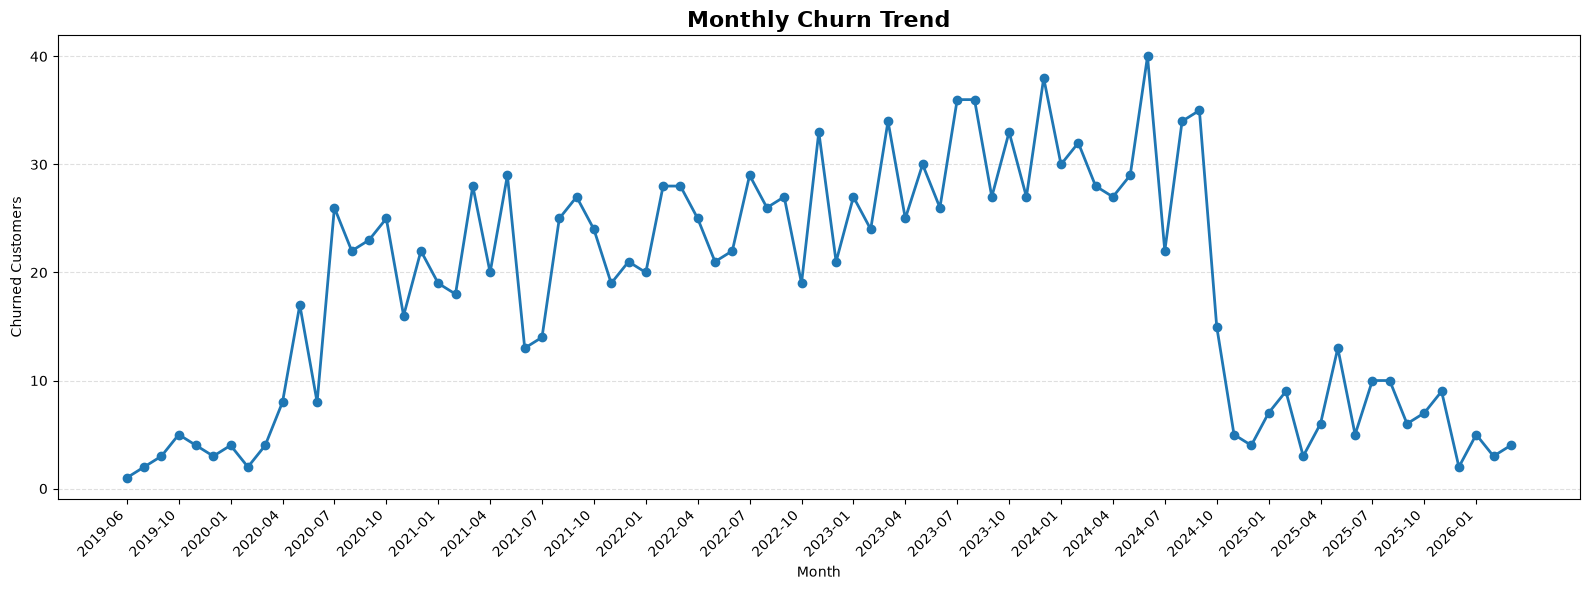

In [46]:
# 1.monthly churn trend (time series KPI)
df_visual['cancellation_month'] = (df_visual['cancellation_date'].dt.to_period('M'))

churn_trend = (
    df_visual[df_visual['churn_flag'] == 1]
    .groupby('cancellation_month')
    .size()
    .sort_index()
)

plt.figure(figsize=(16, 6))
plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    marker='o',
    linewidth=2
)

# Show only every 3rd month on X-axis
plt.xticks(
    range(0, len(churn_trend), 3),
    churn_trend.index.astype(str)[::3],
    rotation=45,
    ha='right'
)

plt.yticks(range(0, int(churn_trend.max()) + 10, 10))
plt.title('Monthly Churn Trend', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

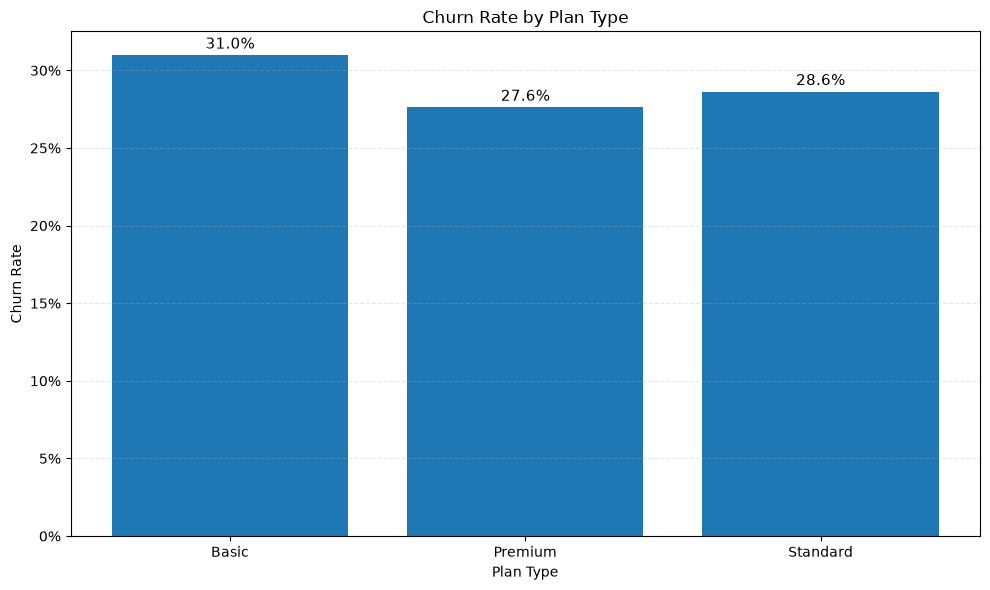

In [47]:
#2. churn by plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# option1:colors = ['red', 'green', 'orange'] -- for mannual colors option
# option2:colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))
plt.figure(figsize=(10,6))
bars = plt.bar(
    churn_plan.index,
    churn_plan.values
)

# Add percentage values on bars
for bar, value in zip(bars, churn_plan.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.002,
        f'{value:.1%}',
        ha='center',
        va='bottom',
        fontsize=11,
    )

# Format Y-axis as percentage
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0%}')
)

plt.xlabel('Plan Type')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Plan Type')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

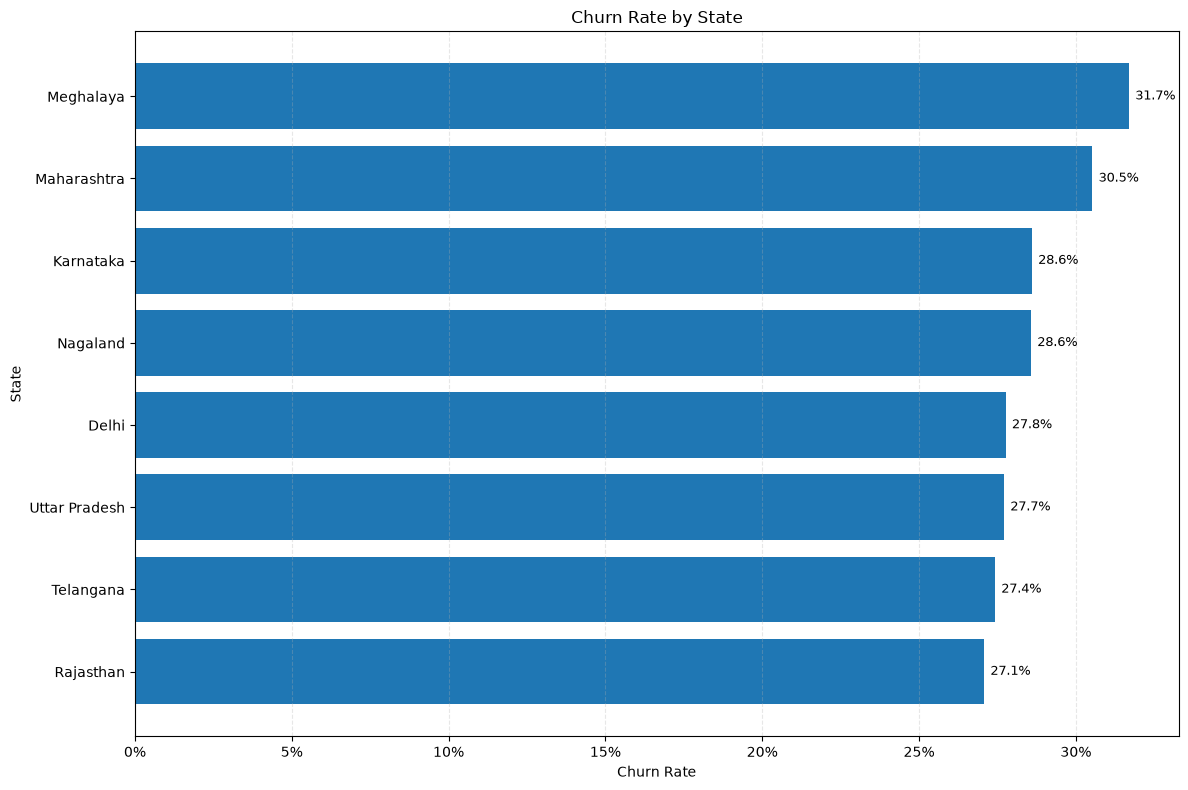

In [48]:
# 3.churn by state
churn_by_state = (
    df_visual.groupby('state')['churn_flag']
    .mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 8))
bars = plt.barh(
    churn_by_state.index,
    churn_by_state.values
)

# Add percentage values
for bar, value in zip(bars, churn_by_state.values):
    plt.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1%}',
        va='center',
        fontsize=9
    )

plt.xlabel('Churn Rate')
plt.ylabel('State')
plt.title('Churn Rate by State')

# Format X-axis as percentage
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0%}')
)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

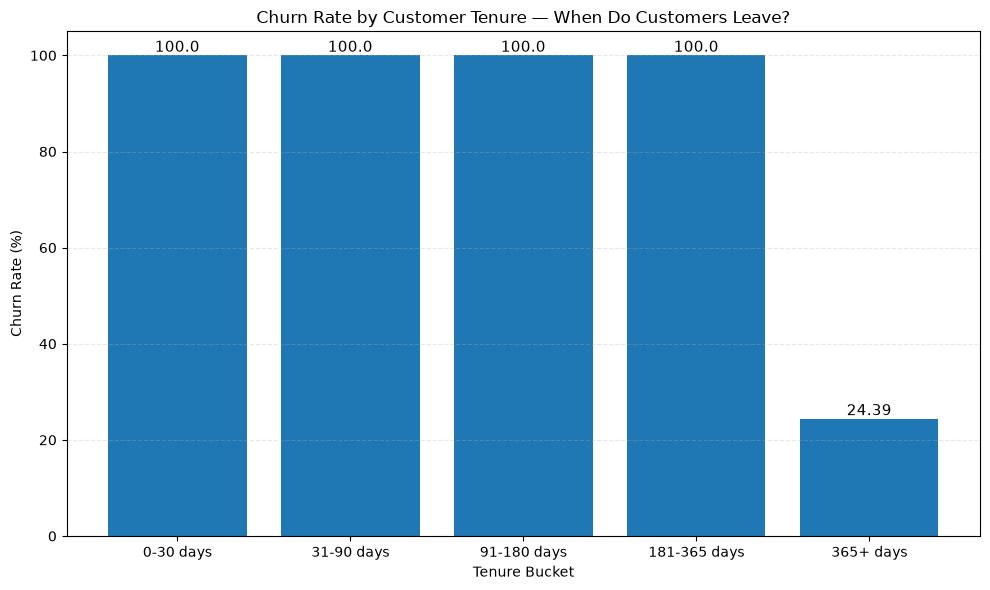

In [49]:
# 4.churn rate by tenure bucket — reveals WHEN customers are most likely to churn
bins = [0, 30, 90, 180, 365, np.inf]
labels = ['0-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days']
df_visual['tenure_bucket'] = pd.cut(df['tenure_days'], bins=bins, labels=labels)

churn_by_tenure = (df_visual.groupby('tenure_bucket')['churn_flag']
                    .mean().mul(100).round(2))

plt.figure(figsize=(10,6))
bars = plt.bar(
    churn_by_tenure.index,
    churn_by_tenure.values
)

# Add percentage values on bars
for bar, value in zip(bars, churn_by_tenure.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.002,
        f'{value}',
        ha='center',
        va='bottom',
        fontsize=11,
    )

plt.title('Churn Rate by Customer Tenure — When Do Customers Leave?')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Tenure Bucket')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

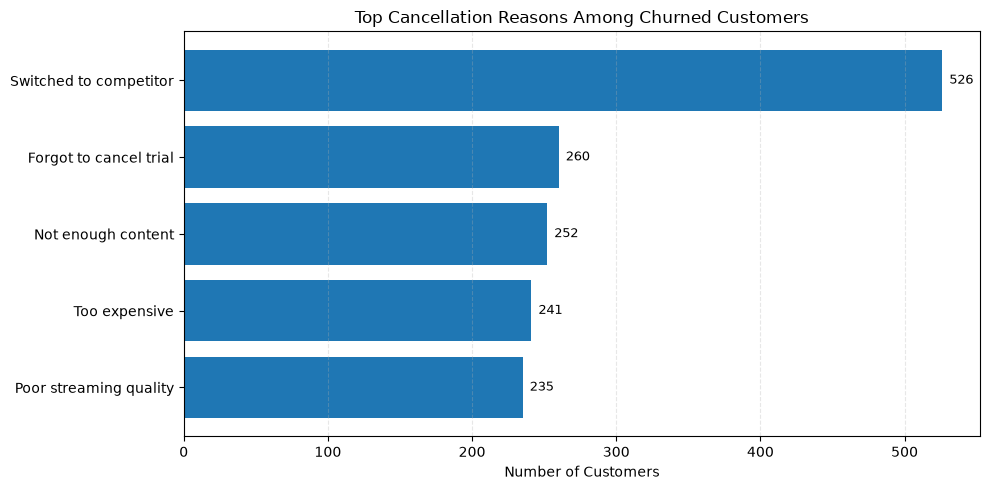

In [50]:
# 5.top cancellation reasons among churned customers
cancel_reasons = (df.loc[df['churn_flag'] == 1, 'cancellation_reason']
                   .value_counts()
                   .sort_values(ascending=True))

plt.figure(figsize=(10, 5))
bars = plt.barh(
    cancel_reasons.index,
    cancel_reasons.values
)

# Add percentage values
for bar, value in zip(bars, cancel_reasons.values):
    plt.text(
        value + 5,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        fontsize=9
    )

plt.title('Top Cancellation Reasons Among Churned Customers')
plt.xlabel('Number of Customers')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
# visualization using seaborn
# encoding - convert str to numeric to find co-relation between features for visualize heatmap

In [52]:
print(df_visual['escalations'].unique())
print(df_visual['escalations'].value_counts(dropna=False))

<StringArray>
[nan, 'Y', 'N']
Length: 3, dtype: str
escalations
NaN    3494
Y       983
N       773
Name: count, dtype: int64


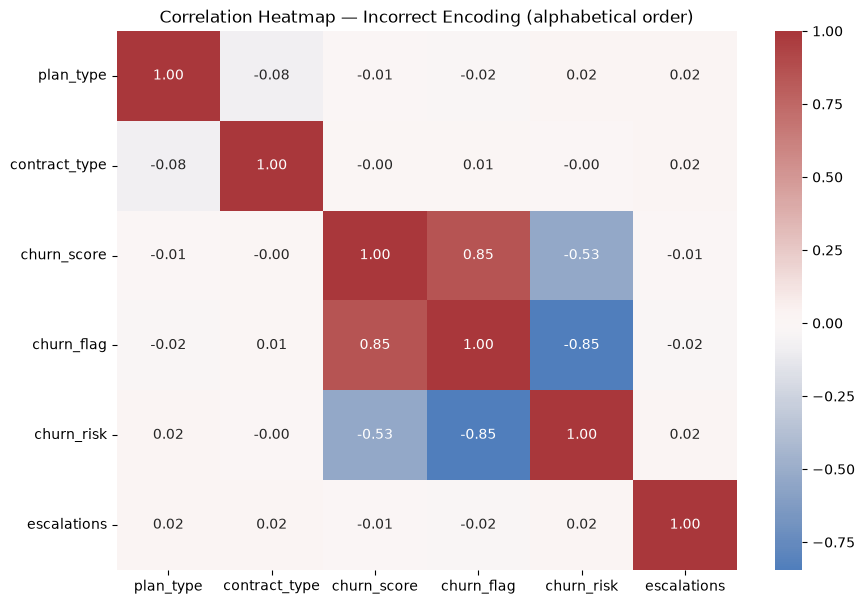

In [53]:
# 6.1.incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].copy()
categorial_cols = ['plan_type','contract_type','churn_risk','escalations']  # ← added escalations here
for col in categorial_cols:
     df_encoded[col] = df_encoded[col].astype('category').cat.codes

# heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df_encoded.corr(),
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
)
plt.title('Correlation Heatmap — Incorrect Encoding (alphabetical order)')
plt.show()

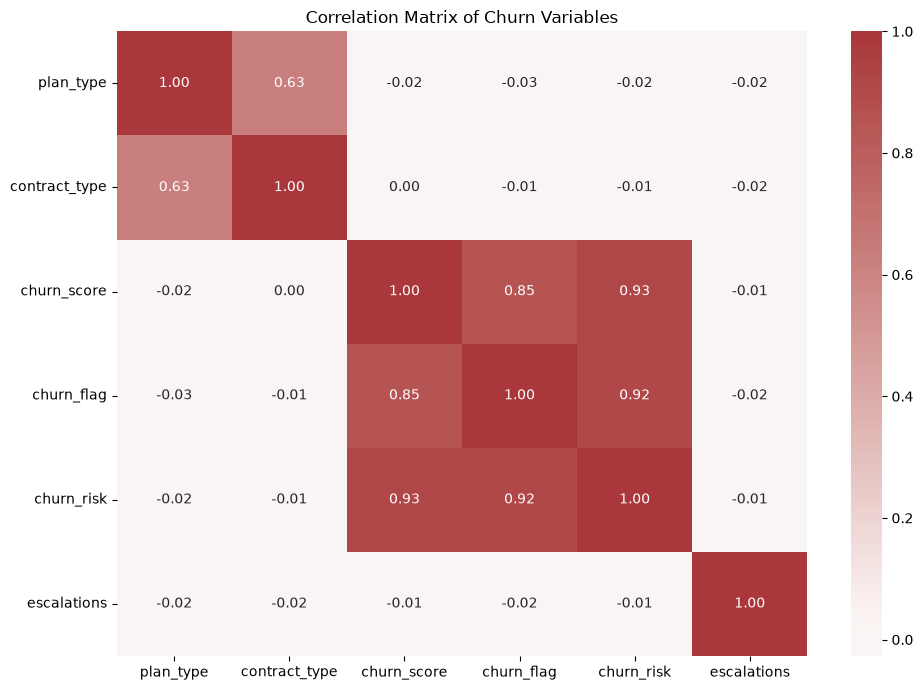

In [54]:
# 6.2.correct method of encoding - based on priority
df_encoded = df_visual[
    [
        'plan_type',
        'contract_type',
        'churn_score',
        'churn_flag',
        'churn_risk',
        'escalations'
    ]
]

order_mapping = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high'],
    'escalations':['N','Y'],
}

for col, order in order_mapping.items():
    df_encoded[col] = pd.Categorical(
        df_encoded[col],
        categories=order,
        ordered=True
    ).codes

# heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_encoded.corr(),
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
)

plt.title('Correlation Matrix of Churn Variables')
plt.tight_layout()
plt.show()

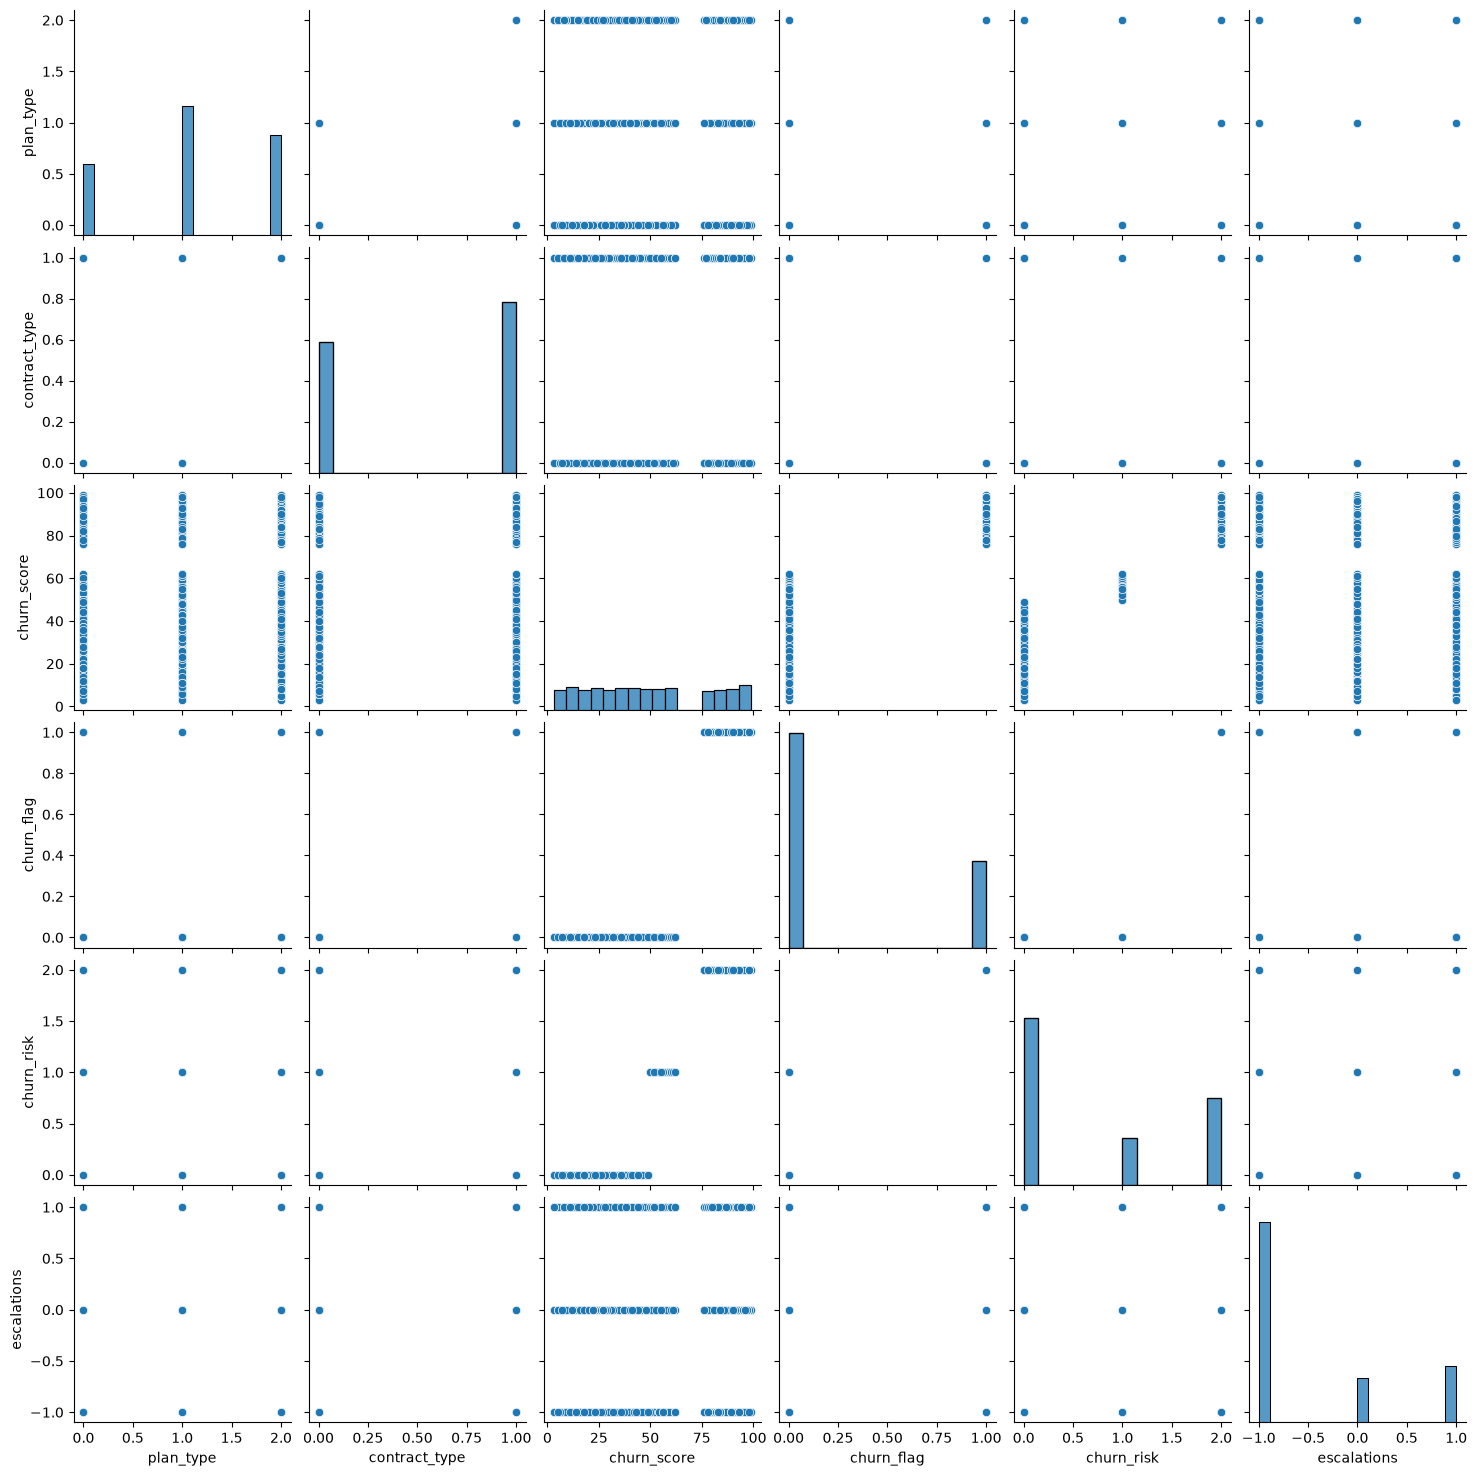

In [55]:
# 7.pairplot - relationship in dataset
sns.pairplot(df_encoded)

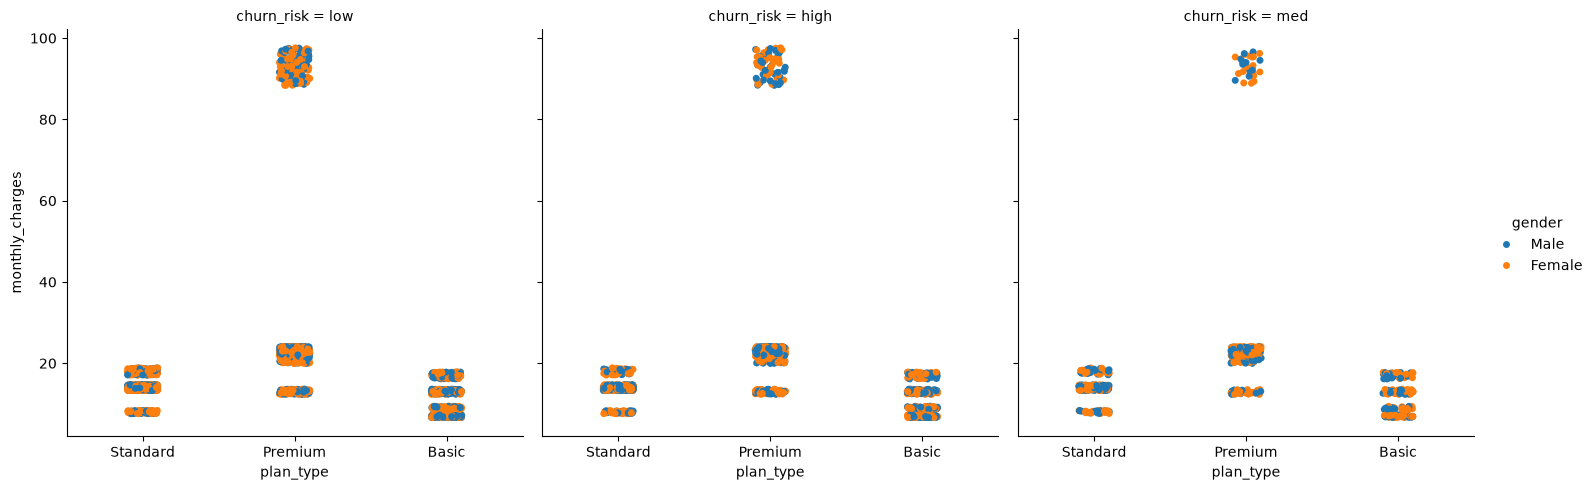

In [56]:
# 8.carplot/facegrid plot
sns.catplot(data=df_visual,
            x='plan_type',
            y='monthly_charges',
            hue='gender',
            col='churn_risk')

In [57]:
# 9.pivot table
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc={
        'monthly_charges':'sum',
        'customerid':'nunique',
        'churn_flag':'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.309677,1240,13420.17
Premium,0.276098,1753,53600.74
Standard,0.286221,2257,31296.54
